# 2D dispersion relation of a synthetic antiferromagnet

This example calculates the dispersion relation of a synthetic antiferromagnet (SAF) for arbitrary directions of the wavevector in the film plane, i.e. a 2D map $f(k_x, k_y)$, with the `DoubleLayerNumeric` class.  The SAF is the one studied by [Adam *et al.*, *npj Spintronics* **3**, 33 (2025)](https://doi.org/10.1038/s44306-025-00095-y): CoFeB(17 nm)/Ru(0.7 nm)/CoFeB(17 nm) in a field of 50 mT applied in the film plane, where the two magnetizations form a *scissors state*.  The resulting map can be compared with their Fig. 3.

The dispersion model follows the supplemental material of [Gallardo *et al.*, *Phys. Rev. Applied* **12**, 034012 (2019)](https://doi.org/10.1103/PhysRevApplied.12.034012), see also the example [Nonreciprocal dispersion of a synthetic antiferromagnet](SAF_dispersion_simple.ipynb) for a 1D dispersion.

> **Frame of reference:** unlike the other dispersion classes of SpinWaveToolkit, where the in-plane angles are measured from the wavevector ($x \parallel \mathbf{k}$), the in-plane angles of `DoubleLayerNumeric` (anisotropy axes, initial and equilibrium magnetization angles) are measured **from the in-plane direction of the external field** $\mathbf{B}_\mathrm{ext}$.  The direction of the wavevector enters only through the parameter `phi`, the angle of $\mathbf{B}_\mathrm{ext}$ measured from $\mathbf{k}$.  This way, the magnetic configuration does not depend on the wavevector, and `kxi` and `phi` can be arrays describing any set of wavevectors.  Layer 1 is the bottom layer (closer to the substrate) and layer 2 the top layer, and the angles are counter-clockwise when viewed from above.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import SpinWaveToolkit as SWT

In [2]:
# material and stack of Adam et al. (2025)
CoFeB = SWT.Material(Ms=1.35e6, Aex=16e-12, alpha=0.011, gamma=28*2e9*np.pi)
d = 17e-9  # (m) thickness of both magnetic layers
s = 0.7e-9  # (m) thickness of the Ru spacer
Jbl = -1.0e-3  # (J/m^2) bilinear interlayer coupling (antiferromagnetic)
Bext = 50e-3  # (T) external field, applied in-plane along x

## Equilibrium of the two magnetizations

For an antiferromagnetically coupled SAF in a field below the saturation field $B_\mathrm{sat} = 2|J_\mathrm{bl}|/(d M_s)$, the two magnetizations form a scissors state symmetric around the field, with $\cos\alpha = d M_s B_\mathrm{ext}/(2|J_\mathrm{bl}|)$ (no anisotropy).  The method `find_equilibria()` returns all equilibria of the energy (polar angles from the film normal, in-plane angles from the field) sorted by energy, with their type (0 = minimum, 1 = maximum, 2 = saddle point); with `in_plane=True`, the magnetizations are restricted to the film plane.  The two scissors states ($\pm\alpha$) are degenerate; `GetEquilibrium()`, which is used by `GetDispersion()`, chooses the one reached from the initial angles `thetaInit1`, `phiInit1`, `thetaInit2`, `phiInit2` (by default in the plane at $\pm 90°$ from the field, i.e. layer 1 ends up with the positive angle).  For an in-plane field as here, the magnetizations stay in the film plane; a partially out-of-plane field (`theta`) or a perpendicular anisotropy (`Ks1`, `Ks2`) tilt them out of the plane, which is included in the equilibrium and in the dispersion.

In [3]:
saf = SWT.DoubleLayerNumeric(Bext, CoFeB, d, kxi=[1e6], theta=np.pi/2,
                             phi=0, Jbl=Jbl, s=s)

alpha = np.arccos(d*CoFeB.Ms*Bext/(2*abs(Jbl)))
print(f"saturation field {2*abs(Jbl)/(d*CoFeB.Ms)*1e3:.1f} mT, "
      + f"scissors half-angle {np.degrees(alpha):.2f} deg")

theta1, phi1, theta2, phi2, eden, type_eq = saf.find_equilibria(in_plane=True)
names = ["minimum", "maximum", "saddle point"]
for p1, p2, e, t in zip(phi1, phi2, eden, type_eq):
    print(f"phi1 = {np.degrees(p1):7.2f}°, phi2 = {np.degrees(p2):7.2f}°, "
          + f"E = {e*1e3:8.4f} mJ/m^2, {names[t]}")

theta1, phi1, theta2, phi2 = saf.GetEquilibrium()
print(f"\nGetEquilibrium(): theta1 = {np.degrees(theta1):.2f}°, phi1 = {np.degrees(phi1):.2f}°, "
      + f"theta2 = {np.degrees(theta2):.2f}°, phi2 = {np.degrees(phi2):.2f}°\n"
      + "(polar angles from the film normal, in-plane angles from Bext)")

saturation field 87.1 mT, scissors half-angle 54.99 deg
phi1 =  -54.99°, phi2 =   54.99°, E = -40.5921 mJ/m^2, minimum
phi1 =   54.99°, phi2 =  -54.99°, E = -40.5921 mJ/m^2, minimum
phi1 =    0.00°, phi2 =    0.00°, E = -40.2288 mJ/m^2, saddle point
phi1 =    0.00°, phi2 = -180.00°, E = -39.9338 mJ/m^2, saddle point
phi1 = -180.00°, phi2 =    0.00°, E = -39.9338 mJ/m^2, saddle point
phi1 = -180.00°, phi2 = -180.00°, E = -35.6388 mJ/m^2, maximum

GetEquilibrium(): theta1 = 90.00°, phi1 = 54.99°, theta2 = 90.00°, phi2 = -54.99°
(polar angles from the film normal, in-plane angles from Bext)


## 2D map of the dispersion relation

We define a grid of wavevectors $(k_x, k_y)$ in the laboratory frame with $\mathbf{B}_\mathrm{ext} \parallel x$.  For each wavevector, `kxi` is its magnitude and `phi` the angle of $\mathbf{B}_\mathrm{ext}$ measured from $\mathbf{k}$, i.e. $\varphi = \varphi_B - \varphi_k$ with $\varphi_k = \mathrm{atan2}(k_y, k_x)$ (note the sign, it matters for the nonreciprocity).  All wavevectors are calculated at once.

In [4]:
kmax, nk = 40e6, 161  # (rad/m) range and number of points of the grid
kx = np.linspace(-kmax, kmax, nk)
kx[nk//2] = 1e-3  # avoid k = 0
KX, KY = np.meshgrid(kx, kx, indexing="xy")
K = np.hypot(KX, KY)  # magnitude of the wavevector
phiB = 0  # (rad) angle of Bext in the laboratory frame (along x)
PHI = phiB - np.arctan2(KY, KX)  # angle of Bext from each wavevector

saf.kxi, saf.phi = K.ravel(), PHI.ravel()
w, v = saf.GetDispersion()  # (2, nk*nk) frequencies of the two SAF modes
f = w.reshape(2, nk, nk)/(2e9*np.pi)  # (GHz)
print(f"uniform acoustic mode: f(k=0) = {f[0, nk//2, nk//2]:.2f} GHz")

uniform acoustic mode: f(k=0) = 6.33 GHz


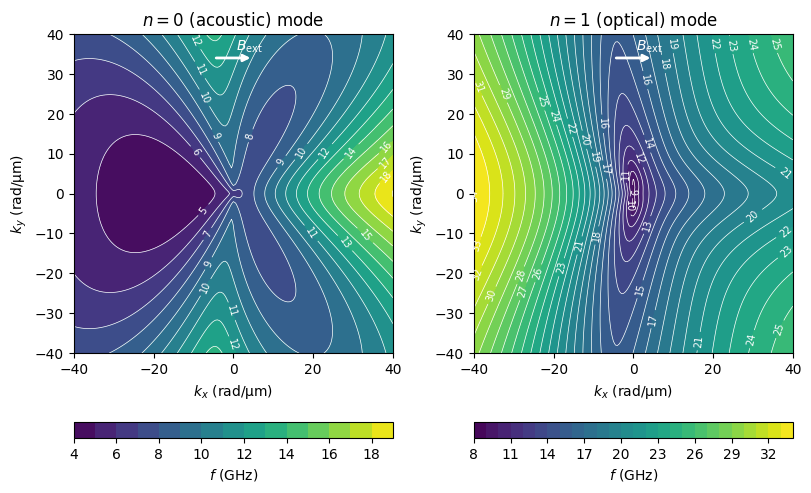

In [5]:
labmod = (r"$n=0$ (acoustic)", r"$n=1$ (optical)")  # lables for modes and
labdir = (r"$k \parallel B_\mathrm{ext}$, nonreciprocal",  # directions
          r"$k \perp B_\mathrm{ext}$, reciprocal")
fig, axs = plt.subplots(1, 2, figsize=(8, 5), constrained_layout=True)
for ax, fi, name in zip(axs, f, labmod):
    levels = np.arange(np.floor(fi.min()), fi.max(), 1.0)
    cf = ax.contourf(KX*1e-6, KY*1e-6, fi, levels=levels, cmap="viridis")
    cs = ax.contour(KX*1e-6, KY*1e-6, fi, levels=levels, colors="w",
                    linewidths=0.5)
    ax.clabel(cs, fmt="%.0f", fontsize=7)
    fig.colorbar(cf, ax=ax, label=f"$f$ (GHz)", location="bottom")
    ax.annotate("", xy=(5, 34), xytext=(-5, 34),
                arrowprops=dict(arrowstyle="-|>", color="w", lw=2))
    ax.text(4, 36, r"$B_\mathrm{ext}$", color="w", ha="center")
    ax.set_xlabel(r"$k_x$ (rad/µm)")
    ax.set_ylabel(r"$k_y$ (rad/µm)")
    ax.set_aspect("equal")
    ax.set_title(f"{name} mode")
plt.show()

The acoustic mode is strongly nonreciprocal along the field ($k_x$ direction, Damon-Eshbach-like geometry with respect to the nearly antiparallel magnetizations) and reciprocal perpendicular to it ($k_y$), in agreement with Fig. 3 of Adam *et al.*  The nonreciprocity comes from the dynamic dipolar coupling of the two layers; its sign depends on which layer is on top (here, the bottom layer 1 has the positive angle $+\alpha$, i.e. the positive $k_y$ component of magnetization), as can be checked by swapping the layers or by using the other scissors state via the `angles` parameter of `GetDispersion()`.

The cuts along the two axes show it more clearly.

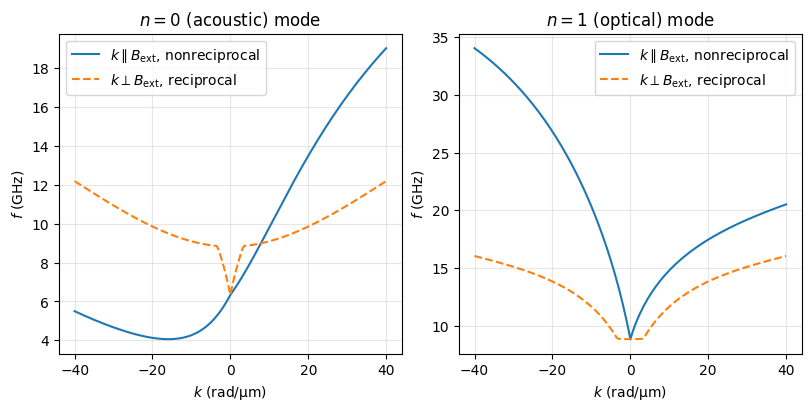

other scissors state = mirrored map: True


In [6]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
for ax, fi, name in zip(axs, f, labmod):
    ax.plot(kx*1e-6, fi[nk//2, :], label=labdir[0])
    ax.plot(kx*1e-6, fi[:, nk//2], "--", label=labdir[1])
    ax.set_xlabel("$k$ (rad/µm)")
    ax.set_ylabel(f"$f$ (GHz)")
    ax.set_title(f"{name} mode")
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

# the other scissors state (phi1 = -alpha, phi2 = +alpha) mirrors the map
f_mirror = saf.GetDispersion(angles=[np.pi/2, -alpha, np.pi/2, alpha])[0].reshape(2, nk, nk)/(2e9*np.pi)
print("other scissors state = mirrored map:",
      np.allclose(f_mirror[0], f[0][:, ::-1], rtol=1e-8))

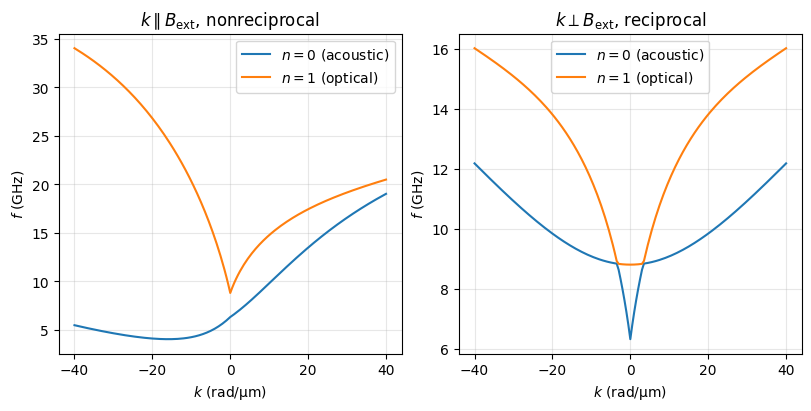

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(8, 4), constrained_layout=True)
for ax, ni, name in zip(axs, (0, 1), labdir):
    fi = f[:, nk//2, :] if ni == 0 else f[:, :, nk//2]
    ax.plot(kx*1e-6, fi[0], label=labmod[0])
    ax.plot(kx*1e-6, fi[1], "-", label=labmod[1])
    ax.set_xlabel("$k$ (rad/µm)")
    ax.set_ylabel(f"$f$ (GHz)")
    ax.set_title(name)
    ax.grid(alpha=0.3)
    ax.legend()
plt.show()

## Crossing of the acoustic and optic modes

`GetDispersion()` sorts the two modes by frequency.  In the cut for $k \perp \mathbf{B}_\mathrm{ext}$ above, the lower branch has a kink at $k \approx 3.3$ rad/µm, where the acoustic mode, which rises steeply in this direction, reaches the almost flat optic mode: on this axis the two modes do not couple and simply cross, so the frequency order of the two branches swaps.  For wavevectors slightly off the axis, the two modes couple (hybridize) and repel each other, and the gap between the frequency-sorted branches opens linearly with $k_x$.  The two modes are therefore degenerate only at the two points $\mathbf{k} = (0, \pm 3.3)$ rad/µm, where the two frequency surfaces touch like two cones.  This is shown below on a finer grid around $k = 0$, with the cuts along $k \perp \mathbf{B}_\mathrm{ext}$ (solid lines) and the two points of degeneracy.

degenerate at ky = ['-3.30', '+3.30'] rad/µm, f = 8.83 GHz; gap 23 MHz on the axis, 969 MHz at kx = 0.5 rad/µm


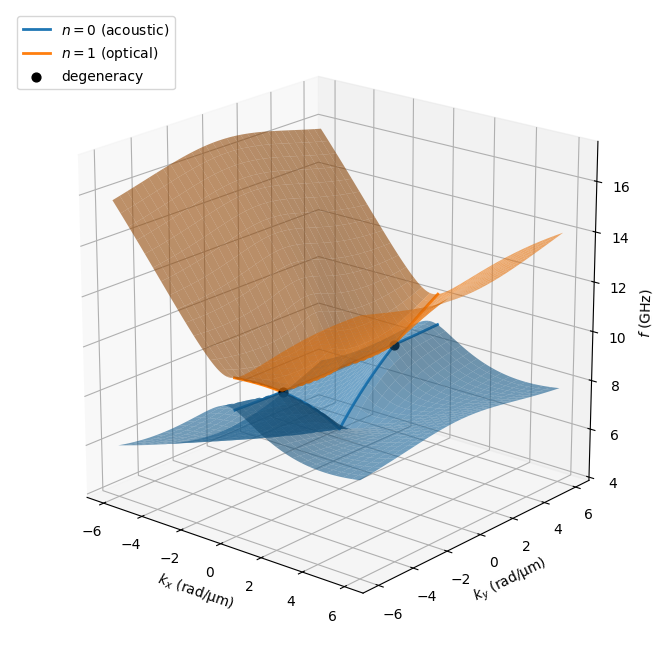

In [8]:
# finer grid around k = 0
kmax3, nk3 = 6e6, 121
kx3 = np.linspace(-kmax3, kmax3, nk3)
kx3[nk3//2] = 1e-3
KX3, KY3 = np.meshgrid(kx3, kx3, indexing="xy")
saf.kxi = np.hypot(KX3, KY3).ravel()
saf.phi = (phiB - np.arctan2(KY3, KX3)).ravel()
f3 = saf.GetDispersion()[0].reshape(2, nk3, nk3)/(2e9*np.pi)  # (GHz) sorted by frequency

# points of degeneracy on the axis kx = 0 (column j)
gap = f3[1] - f3[0]
j = nk3//2
i_deg = [np.argmin(gap[:j, j]), j + np.argmin(gap[j:, j])]
print("degenerate at ky =", [f"{kx3[i]*1e-6:+.2f}" for i in i_deg],
      f"rad/µm, f = {f3[0, i_deg[0], j]:.2f} GHz;",
      f"gap {gap[:, j].min()*1e3:.0f} MHz on the axis, "
      f"{gap[:, j+5].min()*1e3:.0f} MHz at kx = {kx3[j+5]*1e-6:.1f} rad/µm")

fig = plt.figure(figsize=(7, 6.5), constrained_layout=True)
ax = fig.add_subplot(projection="3d")
kw = dict(alpha=0.6, linewidth=0, rstride=4, cstride=4)
KX3, KY3 = KX3*1e-6, KY3*1e-6  # (rad/µm)
ax.plot_surface(KX3, KY3, f3[0], color="C0", **kw)
ax.plot_surface(KX3, KY3, f3[1], color="C1", **kw)
# cuts along k perp. to Bext and the two points of degeneracy
ax.plot(KX3[:, j], KY3[:, j], f3[0, :, j], color="C0", lw=2, label=labmod[0])
ax.plot(KX3[:, j], KY3[:, j], f3[1, :, j], color="C1", lw=2, label=labmod[1])
ax.scatter([0]*2, [kx3[i]*1e-6 for i in i_deg], [f3[0, i, j] for i in i_deg],
           color="k", s=40, depthshade=False, label="degeneracy", zorder=10)
ax.set_xlabel(r"$k_x$ (rad/µm)")
ax.set_ylabel(r"$k_y$ (rad/µm)")
ax.set_zlabel(r"$f$ (GHz)")
ax.legend(loc="upper left")
ax.view_init(elev=20, azim=-50)
ax.set_box_aspect(aspect=(4, 4, 4), zoom=0.95)
plt.show()

> **Note:** the model assumes a uniform dynamic magnetization across the thickness of each layer, so the frequencies become less accurate for thick layers at large wavevectors (here above $\sim 30$ rad/µm for 17 nm thick layers), where the calculation of Adam *et al.* with two slices per layer gives slightly lower frequencies.